# A settlement label needs evidence

**Browser GIS · 15–25 minutes · related project**

A JupyterGIS/JupyterLite atlas distinguishes informal-settlement evidence from a GHSL urban-centre tour.

**Learning question:** Does a built-up-area measurement establish settlement status?

**Source project:** [global-informal-settlements-storymap](https://github.com/jltobias/global-informal-settlements-storymap).

This original index activity is **synthetic teaching analysis**. It uses invented values or authored metadata, no real people or sensitive locations, no remote APIs, and no AI model calls. It is a small companion to the source project, not a reproduction of that project's full course.

![Learning workflow](../../assets/capabilities.svg)

Original atlas diagram, James L. Tobias and contributors, CC BY 4.0; see [asset provenance](../../visual-provenance.ipynb).


## Predict before running

Compare three invented records with explicit source definitions. Count known classifications separately from unknowns; never infer informal status from density alone.

Write a prediction and one assumption you would need to check. Run cells in order with **Shift+Enter**, or **Run → Run All Cells**. The next cell defines only local SVG display helpers; the following cell performs the analysis. Every graphic also prints its values as a text alternative.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Fictional built-up index and source labels: [('T1', 80, 'urban centre'), ('T2', 90, 'unknown'), ('T3', 50, 'source-defined informal')]
Synthetic classification provenance | records: {'urban centre': 1, 'unknown': 1, 'source-defined informal': 1}


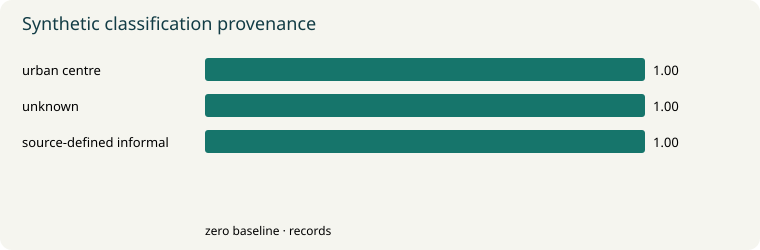

In [2]:
records = [('T1',80,'urban centre'), ('T2',90,'unknown'), ('T3',50,'source-defined informal')]
classes = ['urban centre','unknown','source-defined informal']
counts = {c:sum(label==c for _,_,label in records) for c in classes}
print('Fictional built-up index and source labels:', records)
bars(counts, 'Synthetic classification provenance', 'records')


## Interpret the result

The densest invented record is still unknown. GHSL urban centres describe human settlements; they are not a global informal-settlement classification.

Name the result, the assumption producing it, and one conclusion it cannot support. These are not clinical findings, causal effects or live model outputs.

## Change one thing

Add source, definition, date and license fields, then write a rejection rule for a classification inferred only from urban morphology.

Save a copy with **File → Save and Export Notebook As → Notebook** (or the file browser's Download command). Browser storage is local to this browser/profile; it is not a GitHub commit or shared database.


## Connect the idea

Compare this activity with another chapter on the same [learning path](../../index.ipynb). Keep the question, data status and interpretation visible when transferring a method.


## Sources, continuation and limits

**Source repository:** [global-informal-settlements-storymap](https://github.com/jltobias/global-informal-settlements-storymap).

**Source README:** [reviewed immutable version](https://github.com/jltobias/global-informal-settlements-storymap/blob/1b538de6e714d9fff835a4f35d29d5194834220e/README.md); inspected 2026-11-01, commit `1b538de6e714`. Repository content and linked works keep their original terms. Summaries and exercises here are newly authored.

Source's GHSL tour fetches live JRC data during its build and maps external polygons. Its optional AI panel needs separately configured credentials or a controlled gateway. No GHSL data, AI service or informal-settlement geometry is bundled here.

- [Run source Lab](https://jltobias.github.io/global-informal-settlements-storymap/lab/index.html?path=global/Global_Human_Settlements_Tour.jGIS) - Run the source project notebooks; its dependencies and data terms apply. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)

**Runtime budget:** this default is fewer than 100 values and normally completes within seconds; allow 60 seconds per cell while first loading Python. For native/GPU tools, use the source's local/server guide in an isolated environment, start with one small public/synthetic fixture, limit a trial to 5 minutes, and inspect memory, provider costs and outputs before scaling. For live models, use an approved authenticated backend with server-side secrets and a bounded single request; do not put credentials or sensitive records into a browser. Nothing in this chapter calls those services.

[Central references](../../references.ipynb) · [Contribute](../../contributor-guide.ipynb)


## Browser GIS pathway

**Geographic question:** Does a point or bbox carry the polygon's claim?

**Data readiness (B + C):** normalization lesson, two synthetic XDM features, QA lesson, and classification schema.

**Start from the chapter evidence:** [normalization lesson](../../courses/global-informal-settlements-storymap/notebooks/02_Normalize_Settlements.ipynb) · [two synthetic XDM features](https://github.com/jltobias/JupyterLite-Learning-Atlas/blob/main/content/courses/global-informal-settlements-storymap/data/settlements.geojson) (`courses/global-informal-settlements-storymap/data/settlements.geojson`) · [QA lesson](../../courses/global-informal-settlements-storymap/notebooks/05_Quality_Assurance.ipynb) · [classification schema](https://github.com/jltobias/JupyterLite-Learning-Atlas/blob/main/content/courses/global-informal-settlements-storymap/schemas/settlement.schema.json) (`courses/global-informal-settlements-storymap/schemas/settlement.schema.json`)

- **[RustGIS Web](https://web.rustgis.app/):** Compare existing two synthetic XDM settlements with their point/bbox representations; retain source/classification metadata. In RustGIS, import the reviewed geographic export through Add Data; inspect the selected feature IDs and attribute table before styling.
- **[GeoLibre Web](https://web.geolibre.app/):** Compare existing two synthetic XDM settlements with their point/bbox representations; retain source/classification metadata. In GeoLibre, import that same reviewed file, compare a second legend/filter, and reconcile its count and one known attribute with the notebook.

**Handoff:** Use the [GIS workbench](../../gis-workbench.ipynb) to validate/export an attributed WGS84 layer. Download the GeoJSON, method record and review prompt from `exports/`, then import through the chosen app’s file picker. Compare `_atlas_source_id` (or source `GEOID`) with the original IDs; app-generated internal IDs may differ. Return changed results by explicit upload. Apps and the notebook share no files or kernel state. Practice-only Census data remain Fresno 2020, never this subject’s observations.

**Optional AI prompt (approved subject evidence only):** “Separate source-defined settlement status, morphology and unknown labels. Cite supplied feature IDs/fields, separate observations from assumptions, abstain when evidence is missing, and propose one falsifiable check.” For the common practice package, use its generated schema/summary prompt instead. A human-written answer completes the same task.

**GeoAI opportunity:** Remote classification/AI panel remains optional. Any later fitted exercise must name target/features and spatial/temporal support, reserve a spatial/temporal holdout, inspect leakage and uncertainty, and state evidence that would disprove the interpretation. Styling, thresholds, schema checks and chat alone are not model fitting.

**Human evidence check:** Retain CC0 synthetic declaration; not_fetched context blanks are not zero. Ask the intended reader which decision the map supports; change one legend, filter or annotation, then recheck interpretation against the same IDs and values.

**Continue:** [cross-tool guide and optional Ollama setup](../../browser-gis.ipynb) · [RustGIS assistance](../../courses/rustgis/07_ollama_assistance.ipynb) · [GeoLibre setup](../../courses/geolibre-geoai/18_ollama_geolibre_setup.ipynb) · [chat-to-map](../../courses/geolibre-geoai/19_ollama_chat_to_map.ipynb) · [evidence review](../../courses/geolibre-geoai/20_ollama_evidence_review.ipynb). AI is optional; no service or model is called by this pathway.
